In [1]:
import sys
sys.path.append("..")      # lets you import from src/

import pandas as pd
import matplotlib.pyplot as plt
from src.data_loader import *

In [2]:
for s in DATASETS:
    files = list_files(s)
    x = load_snapshot(files[0])
    print(s, len(files), x.shape, file_timestamp(files[0]), "->", file_timestamp(files[-1]))

set1 2156 (20480, 8) 2003-10-22 12:06:24 -> 2003-11-25 23:39:56
set2 984 (20480, 4) 2004-02-12 10:32:39 -> 2004-02-19 06:22:39
set3 6324 (20480, 4) 2004-03-04 09:27:46 -> 2004-04-18 02:42:55


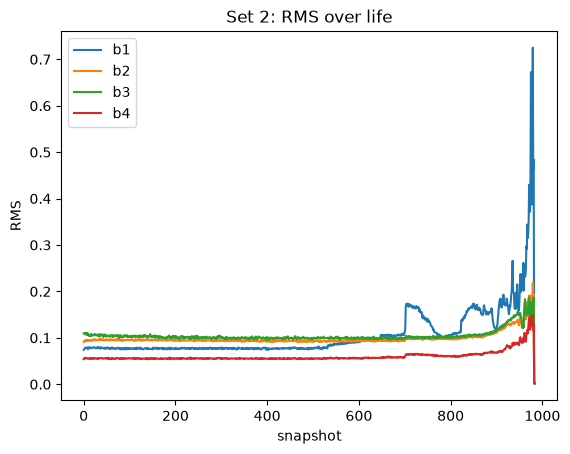

In [3]:
df = pd.read_parquet("../data/processed_features.parquet")

d = df[df["set"] == "set2"]
for b, g in d.groupby("bearing"):
    plt.plot(g["idx"], g["rms"], label=b)
plt.legend(); plt.xlabel("snapshot"); plt.ylabel("RMS"); plt.title("Set 2: RMS over life")
plt.show()

In [4]:
healthy = g[g["idx"] < 0.25 * len(g)]
z = (g["rms"] - healthy["rms"].mean()) / healthy["rms"].std()

In [5]:
g = df[(df["set"] == "set2") & (df["bearing"] == "b4")].tail(5)
print(g[["idx", "timestamp", "rms", "peak", "std"]])

x = load_snapshot(list_files("set2")[-1])
print(x.shape, x.mean(axis=0), x.std(axis=0))

       idx           timestamp       rms   peak       std
21167  979 2004-02-19 05:42:39  0.148351  0.544  0.148322
21171  980 2004-02-19 05:52:39  0.116630  0.527  0.116583
21175  981 2004-02-19 06:02:39  0.130582  0.625  0.130540
21179  982 2004-02-19 06:12:39  0.002154  0.005  0.001204
21183  983 2004-02-19 06:22:39  0.002124  0.005  0.001280
(20480, 4) [-0.00116196 -0.00070117 -0.00066362 -0.00169522] [0.00099955 0.00102114 0.00099632 0.00127987]


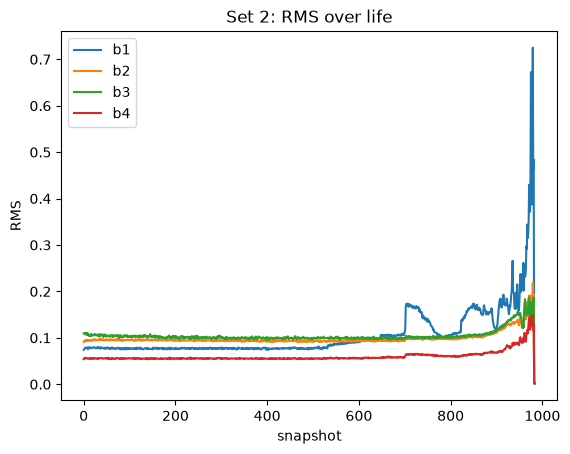

In [8]:
d = df[df["set"] == "set2"]
for b, g in d.groupby("bearing"):
    plt.plot(g["idx"], g["rms"], label=b)
plt.legend(); plt.xlabel("snapshot"); plt.ylabel("RMS"); plt.title("Set 2: RMS over life")

plt.savefig("../results/set2_rms.png", dpi=150, bbox_inches="tight")   # before show
plt.show()